# 01 — Разведочный анализ (EDA)

Цель ноутбука:
1. Показать дисбаланс классов и объяснить, почему accuracy обманчива.
2. Посчитать корреляции и обосновать, какие колонки не идут в витрину.

Данные берутся напрямую из CSV, чтобы ноутбук был воспроизводим без Postgres.

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

IMAGES = Path("../images")
IMAGES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

csv_path = Path("../../ML_HSE/bank_pet_project/bank-additional/bank-additional-full.csv")

raw = pd.read_csv(csv_path, sep=";")
raw = raw.rename(columns={
    "emp.var.rate": "emp_var_rate",
    "cons.price.idx": "cons_price_idx",
    "cons.conf.idx": "cons_conf_idx",
    "nr.employed": "nr_employed",
    "default": "credit_default",
})
raw["subscribed"] = raw["y"].astype(str).str.lower().isin(["yes", "1", "true"]).astype(int)

print(f"Строк: {raw.shape[0]}, колонок: {raw.shape[1]}")
print(f"Пропусков всего: {raw.isna().sum().sum()}")

Строк: 41188, колонок: 22
Пропусков всего: 0


## Дисбаланс классов

Целевая колонка `subscribed` (1 — клиент согласился на депозит).
Классы сильно несбалансированы: соглашаются ~11%, отказываются ~89%.

Поэтому будем использовать не accuracy, а PR-AUC (`average_precision`) + подбирать порог по прибыли 

In [14]:
raw['y'].value_counts()/raw['y'].size*100

y
no     88.734583
yes    11.265417
Name: count, dtype: float64

## Корреляции

Смотрим корреляции между макро-признаками и таргетом, чтобы решить, что оставить
в витрине, а что убрать.

- `duration` сильно связана с ответом, но известна только после звонка — **утечка**, в витрину не идёт.
- `emp_var_rate`, `euribor3m` и `nr_employed` — один экономический фон. В витрину остаётся `nr_employed`.

                emp_var_rate  euribor3m  nr_employed  cons_price_idx  \
emp_var_rate           1.000      0.972        0.907           0.775   
euribor3m              0.972      1.000        0.945           0.688   
nr_employed            0.907      0.945        1.000           0.522   
cons_price_idx         0.775      0.688        0.522           1.000   
cons_conf_idx          0.196      0.278        0.101           0.059   
duration              -0.028     -0.033       -0.045           0.005   
subscribed            -0.298     -0.308       -0.355          -0.136   

                cons_conf_idx  duration  subscribed  
emp_var_rate            0.196    -0.028      -0.298  
euribor3m               0.278    -0.033      -0.308  
nr_employed             0.101    -0.045      -0.355  
cons_price_idx          0.059     0.005      -0.136  
cons_conf_idx           1.000    -0.008       0.055  
duration               -0.008     1.000       0.405  
subscribed              0.055     0.405      

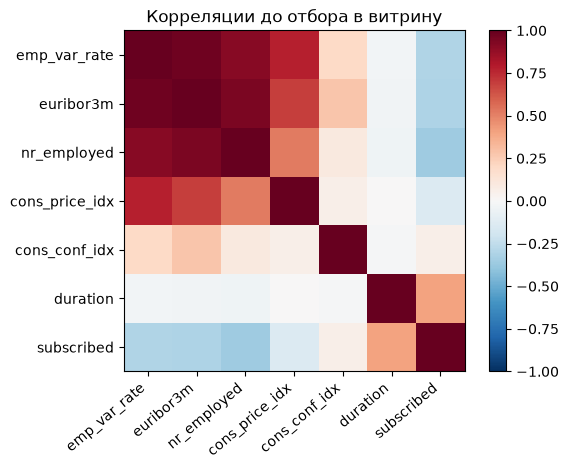

duration и subscribed: 0.405
emp_var_rate и nr_employed: 0.907
euribor3m и nr_employed: 0.945


In [7]:
cols = ["emp_var_rate", "euribor3m", "nr_employed", "cons_price_idx", "cons_conf_idx", "duration", "subscribed"]
corr = raw[cols].corr()
print(corr.round(3))

fig, ax = plt.subplots(figsize=(6.2, 4.8))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=40, ha="right")
ax.set_yticks(range(len(cols)), cols)
fig.colorbar(image, ax=ax, fraction=0.046)
ax.set_title("Корреляции до отбора в витрину")
fig.tight_layout()
plt.show()

print("duration и subscribed:", round(corr.loc["duration", "subscribed"], 3))
print("emp_var_rate и nr_employed:", round(corr.loc["emp_var_rate", "nr_employed"], 3))
print("euribor3m и nr_employed:", round(corr.loc["euribor3m", "nr_employed"], 3))

## `pdays` и `never_contacted`

`pdays` — дни с прошлого контакта. Значение `999` означает «клиенту ещё не звонили».
Как число `999` — выброс, который искажает `StandardScaler` и logreg. Поэтому:

- добавляем бинарный `never_contacted` (1 — не звонили, 0 — звонили),
- `pdays` как число **в модель не идёт**

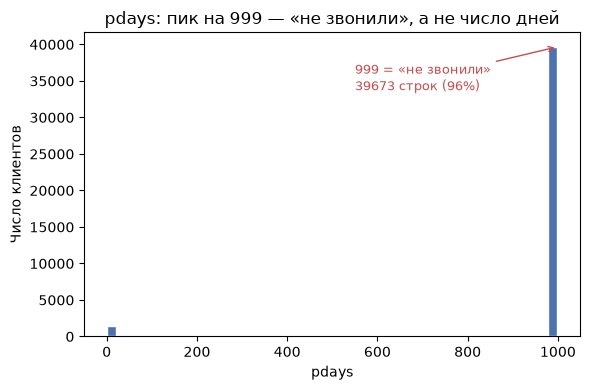

In [26]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))

ax.hist(raw["pdays"], bins=50, color="#4C72B0", edgecolor="white")
ax.set_xlabel("pdays")
ax.set_ylabel("Число клиентов")
ax.set_title("pdays: пик на 999 — «не звонили», а не число дней")

n999 = (raw["pdays"] == 999).sum()
share = n999 / len(raw) * 100
ax.annotate(f"999 = «не звонили»\n{n999} строк ({share:.0f}%)",
            xy=(999, n999), xytext=(550, n999 * 0.85),
            fontsize=9, color="#C44E52",
            arrowprops=dict(arrowstyle="->", color="#C44E52"))

fig.tight_layout()
fig.savefig(IMAGES / "pdays_problem_raw.png", dpi=150, bbox_inches="tight")
plt.show()